# Независимый локальный инференс

Этот notebook запускается в **новом ядре** после training notebooks. Обучающие ячейки исполнять не требуется. Веса, архитектура, POD-базисы, mean/std, геометрия и порядок FEM-узлов загружаются из одного `model.pt`. FEM solver для предсказания не вызывается.

Для демонстрации берём входные A,n,theta,k из сохранённого test. Истинное u используется только для оценки; `predict()` принимает только входные коэффициенты и параметры падающей волны. Новые A,n должны быть в том же порядке FEM-узлов.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BASE = ROOT / 'neural_operator'
DATA_DIR = BASE / 'data' / 'low_frequency'
RUNS = BASE / 'runs' / 'low_frequency'
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.data import load_dataset
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from neural_operator.training import load_predictor
METHOD = 'svd'  # svd, chebyshev, fno
CHECKPOINT = RUNS / METHOD / 'model.pt'
predictor = load_predictor(CHECKPOINT, device='cpu')
dataset = load_dataset(DATA_DIR)
indices = dataset.split_indices()[2][:4]
index = int(indices[0])
prediction = predictor.predict(dataset.A[index], dataset.n[index], dataset.theta[index], dataset.k0[index])
print('Complex output:', prediction.shape, prediction.dtype)
print('Consistent FEM L2:', float(dataset.relative_l2(dataset.u_scat[index], prediction)))


Complex output: (3221,) complex64
Consistent FEM L2: 0.6247777710532496


In [3]:
from time import perf_counter
from neural_operator.diagnostics import write_csv
from neural_operator.training import summarize
rows = []
for method in ['svd', 'chebyshev', 'fno']:
    model = load_predictor(RUNS / method / 'model.pt')
    model.predict_dataset(dataset, indices[:1])  # warm-up
    started = perf_counter()
    batch = model.predict_dataset(dataset, indices)
    seconds = perf_counter() - started
    single = model.predict(dataset.A[index], dataset.n[index], dataset.theta[index], dataset.k0[index])
    difference = float(np.max(np.abs(single - batch[0])))
    np.testing.assert_allclose(single, batch[0], rtol=2e-5, atol=2e-6)
    rows.append({'method': method, **summarize(dataset.relative_l2(dataset.u_scat[indices], batch)),
                 'single_batch_max_difference': difference, 'batch_seconds': seconds})
display_table(rows)
OUT = BASE / 'runs' / 'inference'
OUT.mkdir(parents=True, exist_ok=True)
write_csv(OUT / 'parity.csv', rows)
np.savez_compressed(OUT / 'prediction.npz', index=index, u_scat=prediction,
                    dof_coords=predictor.coordinates, triangles=predictor.triangles)


method,mean,median,p95,max,single_batch_max_difference,batch_seconds
svd,0.78104,0.76516,0.95225,0.96907,0,0.00092929
chebyshev,0.8325,0.82735,0.84902,0.85228,0,0.0016535
fno,0.5052,0.48406,0.64557,0.67381,0,0.0042789


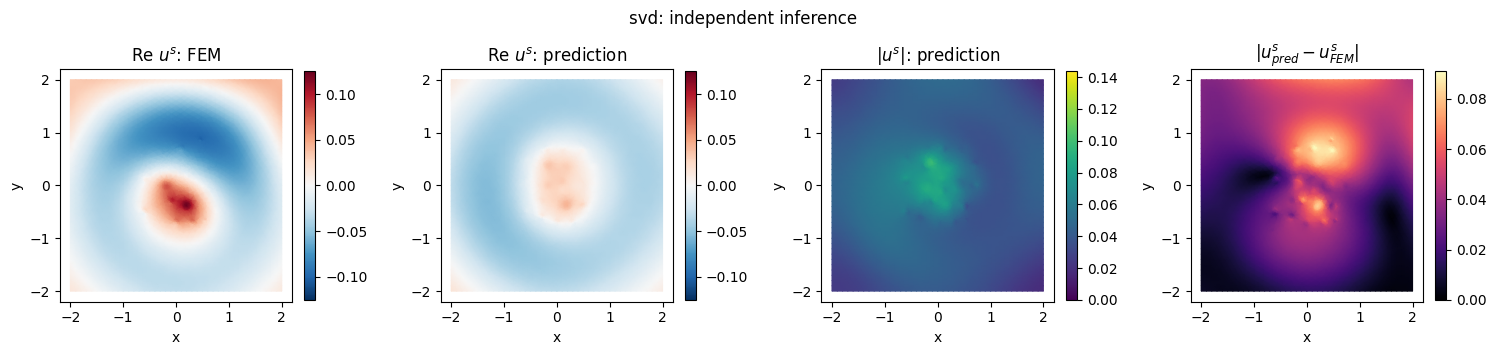

In [4]:
figure = plot_prediction(dataset, index, prediction, title=f'{METHOD}: independent inference')
figure.savefig(OUT / 'prediction.png', dpi=160)
plt.show()


Для внешнего входа загрузите npz с A,n,theta,k0 и передайте их в `predictor.predict(...)`; хранить обучающий датасет для этого не требуется. `predict_dataset()` дополнительно сверяет connectivity и координаты с checkpoint. Изменение геометрии и числа FEM-узлов требует отдельного протокола переноса и в текущий эксперимент не входит.
